# Imports

In [673]:
import pandas as pd
import numpy as np
import sklearn

# Data reading

In [674]:
train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

# EDA

## Feature Records

1. Numerical Columns
- LotFrontage
- LotArea
- YearBuilt
- YearRemodAdd
- MasVnrArea
- BsmtFinSF1
- BsmtFinSF2
- BsmtUnfSF
- TotalBsmtSF
- 1stFlrSF
- 2ndFlrSF
- LowQualFinSF
- GrLivArea
- BsmtFullBath
- BsmtHalfBath
- FullBath
- HalfBath
- Bedroom
- Kitchen
- TotRmsAbvGrd
- Fireplaces
- GarageYrBlt
- GarageArea
- GarageCars
- WoodDeckSF
- OpenPorchSF
- EnclosedPorch
- 3SsnPorch
- ScreenPorch
- PoolArea
- MiscVal
- MoSold
- YrSold

2. Nominal Columns
- MSZoning
- LotConfig
- Neighborhood
- Condition1
- Condition2
- RoofStyle
- RoofMatl
- Exterior1st
- Exterior2nd
- MasVnrType
- Foundation
- Heating
- MiscFeature

3. Ordinal Columns
- MSSubClass
- LotShape
- Street
- Alley
- LandContour
- Utilities
- LandSlope
- Bldgtype
- HouseStyle
- OverallQual
- OverallCond
- ExterQual
- ExterCond
- BsmtQual
- BsmtCond
- BsmtExposure
- BsmtFinType1
- BsmtFinType2
- HeatingQC
- CentralAir
- Electrical
- KitchenQual
- Functional
- FireplaceQu
- GarageType
- GarageFinish
- GarageQual
- GarageCond
- PavedDrive
- PoolQC
- Fence
- SaleType
- SaleCondition

In [675]:
train_df = train_df.drop(columns="Id")
test_df = test_df.drop(columns="Id")

In [676]:
numeric_columns = {
    "LotFrontage",
    "LotArea",
    "YearBuilt",
    "YearRemodAdd",
    "MasVnrArea",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "LowQualFinSF",
    "GrLivArea",
    "BsmtFullBath",
    "BsmtHalfBath",
    "FullBath",
    "HalfBath",
    "BedroomAbvGr",
    "KitchenAbvGr",
    "TotRmsAbvGrd",
    "Fireplaces",
    "GarageYrBlt",
    "GarageArea",
    "GarageCars",
    "WoodDeckSF",
    "OpenPorchSF",
    "EnclosedPorch",
    "3SsnPorch",
    "ScreenPorch",
    "PoolArea",
    "MiscVal",
    "MoSold",
    "YrSold",
    "MSSubClass",
    "OverallQual",
    "OverallCond"
}

In [677]:
nominal_columns = {
    "MSZoning",
    "LotConfig",
    "Neighborhood",
    "Condition1",
    "Condition2",
    "RoofStyle",
    "RoofMatl",
    "Exterior1st",
    "Exterior2nd",
    "MasVnrType",
    "Foundation",
    "Heating",
    "MiscFeature",
    "LandContour",
    "SaleType"
}

In [678]:
ordinal_columns = {
    "LotShape": ["IR3", "IR2", "IR1", "Reg"],
    "Street": ["Grvl", "Pave"],
    "Alley": ["NA", "Grvl", "Pave"],
    "Utilities": ["ELO", "NoSeWa", "NoSewr", "AllPub"],
    "LandSlope": ["Gtl", "Mod", "Sev"],
    "BldgType": ["1Fam", "2fmCon", "Duplex", "TwnhsE", "Twnhs"],
    "HouseStyle": ["1Story", "1.5Unf", "1.5Fin",
                   "2Story", "2.5Unf", "2.5Fin", "SFoyer", "SLvl"],
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "ExterCond": ["Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtQual": ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtCond": ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtExposure": ["NA", "No", "Mn", "Av", "Gd"],
    "BsmtFinType1": ["NA", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFinType2": ["NA", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "HeatingQC": ["Po", "Fa", "TA", "Gd", "Ex"],
    "CentralAir": ["N", "Y"],
    "Electrical": ["SBrkr", "FuseP", "FuseF", "FuseA", "Mix"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Functional": ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "FireplaceQu": ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageType": ["NA", "Detchd", "CarPort", "BuiltIn", "Basment", "Attchd", "2Types"],
    "GarageFinish": ["NA", "Unf", "RFn", "Fin"],
    "GarageQual": ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageCond": ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "PavedDrive": ["N", "P", "Y"],
    "PoolQC": ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "Fence": ["NA", "MnWw", "GdWo", "MnPrv", "GdPrv"],
    "SaleCondition": ["Abnorml", "Partial", "Family", "Alloca", "AdjLand", "Normal"],
}

## Clean Data

In [679]:
def clear_missing(df: pd.DataFrame):
    l = df.columns[df.isna().any()].tolist()
    k = []
    for i in l:
        if 100 * df[i].isna().sum() / len(df[i]) >= 30:
            k.append(i)
    
    df = df.drop(columns=k)
    print(k)
    missing_cols = list(set(l).difference(set(k)))

    return df, missing_cols, k

In [680]:
train_df, train_miss, dropped_cols = clear_missing(train_df)
test_df = test_df.drop(columns = dropped_cols)

['Alley', 'MasVnrType', 'FireplaceQu', 'PoolQC', 'Fence', 'MiscFeature']


In [681]:
def feature_split(cols):
    numeric = set(cols).intersection(numeric_columns)
    nominal = set(cols).intersection(nominal_columns)
    ordinal = set(cols).intersection(ordinal_columns.keys())

    return numeric, nominal, ordinal

In [682]:
train_numeric, train_nominal, train_ordinal = feature_split(train_df.columns)
test_numeric, test_nominal, test_ordinal = feature_split(test_df.columns)

In [683]:
from sklearn.impute import SimpleImputer
def simple_impute(df, cols, type, missing_val=np.nan, fill_val = None):
    imputer = SimpleImputer(strategy=type, missing_values=missing_val,
                            fill_value=fill_val)
    df[cols] = imputer.fit_transform(df[cols])

    return df, imputer

In [684]:
train_df, train_numeric_imputer = simple_impute(train_df,
                                                list(train_numeric),
                                                type="median")
test_df[list(test_numeric)] = train_numeric_imputer.transform(test_df[list(test_numeric)])

In [685]:
train_df, train_ordinal_imputer = simple_impute(train_df,
                                                list(train_ordinal),
                                                "most_frequent")
test_df[list(test_ordinal)] = train_ordinal_imputer.transform(test_df[list(test_ordinal)])

In [686]:
train_df, train_nominal_imputer = simple_impute(train_df,
                                                list(train_nominal),
                                                "most_frequent")
test_df[list(test_nominal)] = train_nominal_imputer.transform(test_df[list(test_nominal)])

In [687]:
def clear_sparse(df: pd.DataFrame):
    k = []

    for i in numeric_columns:
        if i not in df.columns:
            continue
        
        if len(df[df[i] == 0]) > 3 * len(df) // 4:
            k.append(i)

    df = df.drop(columns=k)
    print(k)

    # for i in nominal_columns:
    #     if i not in df.columns:
    #         continue

    #     vals = df[i].value_counts(normalize=True)
    #     if len(vals) > 2:
    #         valid_categories = vals[vals >= 0.01].index
    #         df = df[df[i].isin(valid_categories)]
    #         print(i)
    
    # for i in ordinal_columns.keys():
    #     if i not in df.columns:
    #         continue
        
    #     vals = df[i].value_counts(normalize=True)
    #     if len(vals) > 2:
    #         valid_categories = vals[vals >= 0.01].index
    #         df = df[df[i].isin(valid_categories)]
    #         print(i)

    return df, k

In [688]:
train_df, dropped_cols1 = clear_sparse(train_df)
test_df = test_df.drop(columns=dropped_cols1)

['MiscVal', 'BsmtFinSF2', 'BsmtHalfBath', 'PoolArea', 'EnclosedPorch', 'ScreenPorch', 'LowQualFinSF', '3SsnPorch']


# Feature Visualization

In [572]:
import math
import matplotlib.pyplot as plt

In [573]:
def bar_chart_grid(df: pd.DataFrame, ncols: int = 4, bins: int = 15, max_categories: int = 20):
    n = len(df.columns)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3))
    axes = axes.flatten()

    for ax, col in zip(axes, df.columns):
        s = df[col].dropna()
        if s.empty:
            ax.set_visible(False); continue

        if pd.api.types.is_numeric_dtype(s):
            counts, edges, _ = ax.hist(s, bins=bins, color="steelblue", edgecolor="white")
            ax.set_xticks([])  # numeric ticks get crowded; histogram shape is the point
        else:
            vc = s.value_counts().head(max_categories)
            ax.bar(vc.index.astype(str), vc.values, color="steelblue")
            ax.tick_params(axis="x", rotation=60, labelsize=7)

        ax.set_title(col, fontsize=10)

    # hide unused subplots
    for ax in axes[n:]:
        ax.set_visible(False)

    fig.tight_layout()
    return fig

# Usage
# fig = bar_chart_grid(df)
# fig.savefig("all_columns_bars.png", dpi=120, bbox_inches="tight")

In [574]:
for name, cols in {
    "numerical": numeric_columns,
    "nominal":   nominal_columns,
    "ordinal":   ordinal_columns,
}.items():
    cols = [c for c in cols if c in test_df.columns]
    fig = bar_chart_grid(test_df[cols], ncols=4)
    fig.savefig(f"test_bars_{name}.png", dpi=120, bbox_inches="tight")
    plt.close(fig)

In [575]:
for name, cols in {
    "numerical": numeric_columns,
    "nominal":   nominal_columns,
    "ordinal":   ordinal_columns,
}.items():
    cols = [c for c in cols if c in train_df.columns]
    fig = bar_chart_grid(train_df[cols], ncols=4)
    fig.savefig(f"train_bars_{name}.png", dpi=120, bbox_inches="tight")
    plt.close(fig)

# Encode

In [690]:
import pandas as pd
from sklearn.feature_extraction import FeatureHasher

def nominal_encode(df, cols, hasher=None):
    cols = list(set(df.columns).intersection(set(cols)))
    dict_data = df[cols].astype(str).to_dict(orient='records')

    if hasher is None:
        hasher = FeatureHasher(n_features=len(cols), input_type='dict')
    df[cols] = hasher.transform(dict_data).toarray()

    return df, hasher

In [691]:
train_df, train_nom_enc = nominal_encode(train_df, list(nominal_columns))
test_df, _ = nominal_encode(test_df, list(nominal_columns), train_nom_enc)

In [692]:
from sklearn.preprocessing import OrdinalEncoder
def ordinal_encode(df, ord_dict, cols=None, ord_enc=None):
    if cols is None:
        cols = df.columns
        cols = list(set(cols).intersection(set(df.columns)))

    is_train = True if ord_enc is None else False
    if is_train:
        ord_enc = {}
    
    for col, cats in ord_dict.items():
        if col in cols:
            print(col)
            
            if is_train:
                enc = OrdinalEncoder(categories=[cats], handle_unknown="use_encoded_value",
                                     unknown_value=np.nan)
                df[col] = enc.fit_transform(df[[col]])
                ord_enc[col] = enc
            else:
                df[col] = ord_enc[col].transform(df[[col]])
    
    return df, ord_enc

In [693]:
train_df, train_ord_enc = ordinal_encode(train_df, ordinal_columns)
test_df, _ = ordinal_encode(test_df, ordinal_columns,
                            cols=train_df.columns, ord_enc=train_ord_enc)

LotShape
Street
Utilities
LandSlope
BldgType
HouseStyle
ExterQual
ExterCond
BsmtQual
BsmtCond
BsmtExposure
BsmtFinType1
BsmtFinType2
HeatingQC
CentralAir
Electrical
KitchenQual
Functional
GarageType
GarageFinish
GarageQual
GarageCond
PavedDrive
SaleCondition
LotShape
Street
Utilities
LandSlope
BldgType
HouseStyle
ExterQual
ExterCond
BsmtQual
BsmtCond
BsmtExposure
BsmtFinType1
BsmtFinType2
HeatingQC
CentralAir
Electrical
KitchenQual
Functional
GarageType
GarageFinish
GarageQual
GarageCond
PavedDrive
SaleCondition


In [694]:
# def select(df):
#     exterior_1st_conditions = [
#         (df["Exterior1st"] == "VinlySd"),
#         (df["Exterior1st"].isin(["MetalSd", "HdBoard", "Wd Sdng"]))
#     ]
#     exterior_1st_choices = ["VinylSd", "Other", "Minor"]

#     df["Exterior1st"] = np.select(exterior_1st_conditions,
#                                   exterior_1st_choices,
#                                   default="Constant_Value")

#     exterior_2nd_conditions = [
#         (df["Exterior2nd"] == "VinlySd"),
#         (df["Exterior2nd"].isin(["MetalSd", "HdBoard", "Wd Sdng", "Plywood"]))
#     ]
#     exterior_2nd_choices = ["VinylSd", "Other", "Minor"]

#     df["Exterior2nd"] = np.select(exterior_2nd_conditions,
#                                   exterior_2nd_choices,
#                                   default="Constant_Value")

#     foundation_conditions = [
#         (df['Foundation'].isin(["PConc", "CBlock"])),
#         (df["Foundation"] == "BrkTil")
#     ]
#     foundation_choices = ["Main", "BrkTil", "Other"]

#     df["Foundation"] = np.select(foundation_conditions,
#                                     foundation_choices,
#                                     default="Constant_Value")

#     df["Condition1"] = np.where(df["Condition1"] == "Norm", 1, 0)
#     df["Condition2"] = np.where(df["Condition1"] == "Norm", 1, 0)
#     df["LandCountour"] = np.where(df["LandContour"] == "Lvl", 1, 0)
#     df["Heating"] = np.where(df["Heating"] == "GsA", 1, 0)
#     df["MiscFeature"] = np.where(df["MiscFeature"] == "Shed", 1, 0)
#     df["MSZoning"] = np.where(df["MSZoning"] == "RL", 1, 0)
#     df["RoofMatl"] = np.where(df["RoofMatl"] == "CompShg", 1, 0)
#     df["SaleType"] = np.where(df["SaleType"] == "WD", 1, 0)
#     df["LotConfig"] = np.where(df["LotConfig"] == "inside", 1, 0)
#     df["RoofStyle"] = np.where(df["RoofStyle"] == "Gable", 1, 0)

#     return df

# Feature Transformation

In [695]:
target = "SalePrice"
train_X, train_y = train_df.drop(columns=target), train_df[target]

In [696]:
from sklearn.preprocessing import RobustScaler

def numeric_scale(df, scaler=None):
    cols = list(set(df.columns).intersection(numeric_columns))

    if scaler is None:
        scaler = RobustScaler()
    
    df[cols] = scaler.fit_transform(df[cols])

    return df, scaler

In [697]:
train_X, train_numeric_scaler = numeric_scale(train_X)
test_df, _ = numeric_scale(test_df, train_numeric_scaler)

# Feature Selection

# Train

In [698]:
from sklearn.linear_model import LinearRegression

In [ ]:
lin_reg = LinearRegression()
lin_reg.fit(train_X, train_y)
pred_y = lin_reg.predict(test_df)

<Axes: >

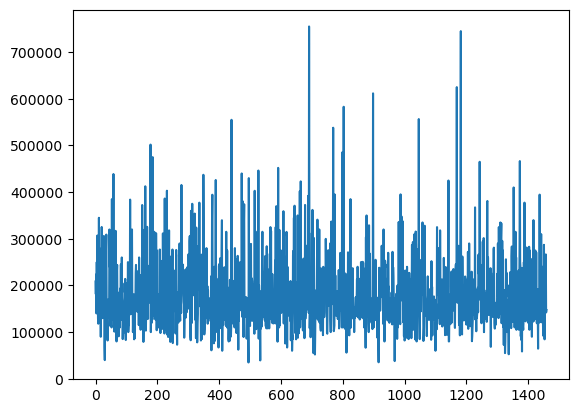

In [702]:
train_y.plot()

<Axes: >

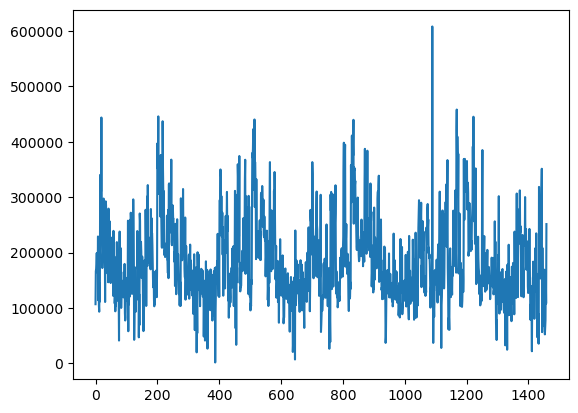

In [703]:
pd.Series(pred_y).plot()